# 🫀 Exercise: Heart Disease Prediction Using Machine Learning and PCA

| | |
|---|---|
| **Dataset** | Heart Failure Prediction Dataset |
| **Source** | [Kaggle – Heart Failure Prediction](https://www.kaggle.com/fedesoriano/heart-failure-prediction) |
| **File name** | `heart.csv` |
| **Folder** | `Exercise` |

**Student Name:** Bhavya Garg &nbsp;&nbsp; **Roll No.:** 1RUA25CSE0115 &nbsp;&nbsp; **Date:** 11/11/26

---

## Problem Statement

Download the `heart.csv` dataset from Kaggle and save it in the `Exercise` folder. Perform data preprocessing, model building, hyperparameter tuning and dimensionality reduction to predict whether a patient has heart disease (`HeartDisease` = 1) or not (`HeartDisease` = 0).

### Instructions
- Write your code in the **empty code cells** provided below each task.
- Write your explanations in the **✍️ Your answer** cells.
- Run all cells from top to bottom before submitting (**Kernel → Restart & Run All**).
- Use `random_state=42` wherever randomness is involved so that results are reproducible.

## Overall Workflow

You will build the pipeline below. Path A trains models on all preprocessed features; Path B trains the same models on PCA-reduced features. Step 9 compares the two.

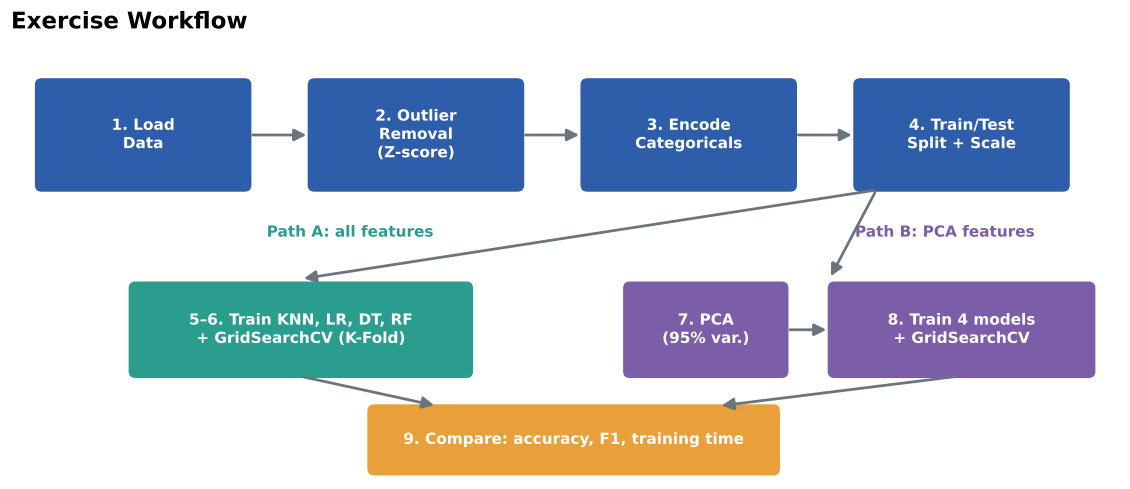

## Data Dictionary

| Feature | Description | Type |
|---|---|---|
| `Age` | Age of the patient (years) | Numerical |
| `Sex` | Sex of the patient (`M`, `F`) | Categorical (binary) |
| `ChestPainType` | `TA` typical angina, `ATA` atypical angina, `NAP` non-anginal pain, `ASY` asymptomatic | Categorical (nominal) |
| `RestingBP` | Resting blood pressure (mm Hg) | Numerical |
| `Cholesterol` | Serum cholesterol (mg/dl) | Numerical |
| `FastingBS` | Fasting blood sugar > 120 mg/dl (1 = yes, 0 = no) | Binary (already numeric) |
| `RestingECG` | Resting ECG result (`Normal`, `ST`, `LVH`) | Categorical (nominal) |
| `MaxHR` | Maximum heart rate achieved | Numerical |
| `ExerciseAngina` | Exercise-induced angina (`Y`, `N`) | Categorical (binary) |
| `Oldpeak` | ST depression induced by exercise | Numerical |
| `ST_Slope` | Slope of the peak exercise ST segment (`Up`, `Flat`, `Down`) | Categorical |
| `HeartDisease` | **Target** — 1 = heart disease, 0 = normal | Binary |

## Import Libraries

Import all the libraries you will need (pandas, numpy, matplotlib/seaborn, scipy, scikit-learn modules, `time`, etc.).

In [39]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import time
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

---
## Task 1: Load the Dataset

1. Load `Exercise/heart.csv` into a Pandas DataFrame.
2. Display the first five records.
3. Examine the dataset's **dimensions**, **column names**, **data types** and **missing values**.

### 1.1 Load the dataset and display the first five records

In [40]:
df = pd.read_csv('heart.csv')
df.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


### 1.2 Dimensions, column names and data types

In [41]:
print(df.shape)
print(df.columns)
df.info()

(918, 12)
Index(['Age', 'Sex', 'ChestPainType', 'RestingBP', 'Cholesterol', 'FastingBS',
       'RestingECG', 'MaxHR', 'ExerciseAngina', 'Oldpeak', 'ST_Slope',
       'HeartDisease'],
      dtype='str')
<class 'pandas.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    str    
 2   ChestPainType   918 non-null    str    
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    str    
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    str    
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    str    
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), str(5)
memory usage: 86.2 KB


### 1.3 Check for missing values

In [42]:
print(df.isnull().sum())
df.describe()

Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64


,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease
count,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000
mean,53.510893,132.396514,198.799564,0.233115,136.809368,0.887364,0.553377
std,9.432617,18.514154,109.384145,0.423046,25.460334,1.066570,0.497414
min,28.000000,0.000000,0.000000,0.000000,60.000000,-2.600000,0.000000
25%,47.000000,120.000000,173.250000,0.000000,120.000000,0.000000,0.000000
50%,54.000000,130.000000,223.000000,0.000000,138.000000,0.600000,1.000000
75%,60.000000,140.000000,267.000000,0.000000,156.000000,1.500000,1.000000
max,77.000000,200.000000,603.000000,1.000000,202.000000,6.200000,1.000000


### 1.4 (Optional) Class balance
Check how many records belong to each class of `HeartDisease`. Is the dataset balanced?

HeartDisease
1    508
0    410
Name: count, dtype: int64


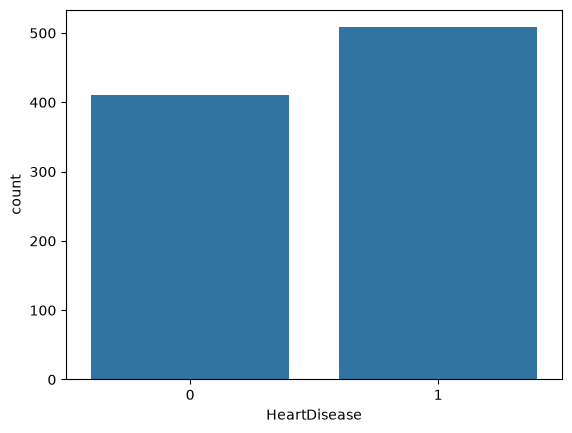

In [43]:
print(df['HeartDisease'].value_counts())
sns.countplot(x='HeartDisease', data=df)
plt.show()

**Q1.** Summarise your observations: number of rows/columns, which columns are text-based, and whether any missing values exist.

> 💡 *Hint:* Look closely at `Cholesterol` and `RestingBP` using `df.describe()`. Are there values that are medically impossible (e.g., 0)? Note them — such values are sometimes hidden missing values.

> ✍️ **Your answer:**
>
> From inspecting the dataset with `shape`, `info()`, `isnull().sum()`, and `describe()`:
> - **Dimensions:** The dataset has 918 rows and 12 columns.
> - **Categorical (text) features:** There are 5 text-based features: `Sex`, `ChestPainType`, `RestingECG`, `ExerciseAngina`, and `ST_Slope`.
> - **Numerical features:** The remaining columns are numerical: `Age`, `RestingBP`, `Cholesterol`, `FastingBS` (0 or 1), `MaxHR`, `Oldpeak`, and `HeartDisease` (target).
> - **Missing values:** `df.isnull().sum()` reports 0 across all columns, meaning there are no explicit null or NaN values in the dataset.
> - **Hidden missing values / anomalies:** In `df.describe()`, `RestingBP` has a minimum value of 0 (in 1 row) and `Cholesterol` has a minimum value of 0 (in 172 rows). A resting blood pressure or cholesterol reading of 0 is physiologically impossible in a living patient, so these zero values represent hidden missing / unrecorded data points.
> - **Class balance:** The target variable `HeartDisease` contains 508 patients with heart disease (55.3%) and 410 healthy patients (44.7%), which represents a well-balanced distribution with no extreme skew.

---
## Task 2: Outlier Detection and Removal (Z-score Method)

The Z-score measures how many standard deviations a value lies from the mean of its feature:

$$z = \frac{x - \mu}{\sigma}$$

A record is treated as an **outlier** if **any** of its numerical features has $z > +3$ or $z < -3$.

![zscore](attachment:zscore.png)

**Steps**
1. Select the numerical (continuous) features: `Age`, `RestingBP`, `Cholesterol`, `MaxHR`, `Oldpeak`.
2. Calculate the Z-score for each of these features.
3. Identify and count the records containing outliers.
4. Remove those records and report the shape of the dataset before and after removal.

> ⚠️ Do **not** compute Z-scores on the target column or on encoded/binary columns.

### 2.1 Visualise the numerical features (e.g., boxplots) before outlier removal

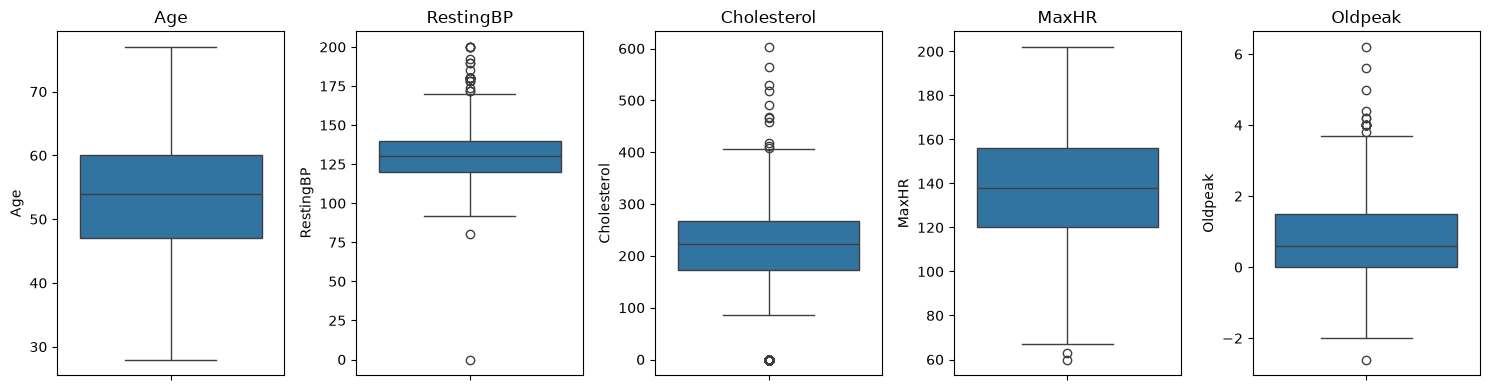

In [44]:
num_cols = ['Age', 'RestingBP', 'Cholesterol', 'MaxHR', 'Oldpeak']
plt.figure(figsize=(15, 4))
for i, col in enumerate(num_cols, 1):
    plt.subplot(1, 5, i)
    sns.boxplot(y=df[col])
    plt.title(col)
plt.tight_layout()
plt.show()

### 2.2 Calculate Z-scores for the numerical features

In [45]:
num_cols = ['Age', 'RestingBP', 'Cholesterol', 'MaxHR', 'Oldpeak']
z_scores = np.abs(stats.zscore(df[num_cols]))
z_scores_df = pd.DataFrame(z_scores, columns=num_cols)
z_scores_df.head()

,Age,RestingBP,Cholesterol,MaxHR,Oldpeak
0,1.433140,0.410909,0.825070,1.382928,0.832432
1,0.478484,1.491752,0.171961,0.754157,0.105664
2,1.751359,0.129513,0.770188,1.525138,0.832432
3,0.584556,0.302825,0.139040,1.132156,0.574711
4,0.051881,0.951331,0.034755,0.581981,0.832432


### 2.3 Identify and count the outlier records

In [46]:
outliers_per_col = (z_scores_df > 3).sum()
print(outliers_per_col)
outlier_mask = (z_scores_df > 3).any(axis=1)
print(outlier_mask.sum())

Age            0
RestingBP      8
Cholesterol    3
MaxHR          1
Oldpeak        7
dtype: int64
19


### 2.4 Remove the outliers and display the new shape

In [47]:
print(df.shape)
df_clean = df[~outlier_mask].copy()
print(df_clean.shape)

(918, 12)
(899, 12)


**Q2.** How many records were removed? Which feature contributed the most outliers?

> ✍️ **Your answer:**
>
> A total of **19 records** were flagged as outliers having a Z-score with absolute value greater than 3 and removed. The dataset size changed from 918 records to 899 records.
>
> Feature breakdown of outliers:
> - `RestingBP`: 8 outliers
> - `Oldpeak`: 7 outliers
> - `Cholesterol`: 3 outliers
> - `MaxHR`: 1 outlier
> - `Age`: 0 outliers
>
> **RestingBP** contributed the highest number of outliers (8 records), followed closely by **Oldpeak** (7 records).

---
## Task 3: Data Encoding

Machine learning models need numerical input, so text-based features must be encoded.

![encoding](attachment:encoding.png)

| Technique | Use it when... | Example features |
|---|---|---|
| **Label Encoding** | The feature is **binary** (2 categories) or has a natural order | `Sex`, `ExerciseAngina` |
| **One-Hot Encoding** | The feature is **nominal** with more than 2 categories (no order) | `ChestPainType`, `RestingECG`, `ST_Slope` |

> 💡 Applying Label Encoding to a nominal feature (e.g., ATA=0, NAP=1, ASY=2) makes the model think ASY > NAP > ATA, which is not meaningful.

**Steps**
1. Identify the categorical (text-based) features.
2. Apply **Label Encoding** to the binary features.
3. Apply **One-Hot Encoding** to the nominal features (consider `drop_first=True` to avoid the dummy-variable trap).
4. Display the encoded DataFrame and its new shape.

### 3.1 Identify the categorical features and their unique values

In [48]:
cat_cols = ['Sex', 'ChestPainType', 'RestingECG', 'ExerciseAngina', 'ST_Slope']
for col in cat_cols:
    print(col, df_clean[col].unique())

Sex <StringArray>
['M', 'F']
Length: 2, dtype: str
ChestPainType <StringArray>
['ATA', 'NAP', 'ASY', 'TA']
Length: 4, dtype: str
RestingECG <StringArray>
['Normal', 'ST', 'LVH']
Length: 3, dtype: str
ExerciseAngina <StringArray>
['N', 'Y']
Length: 2, dtype: str
ST_Slope <StringArray>
['Up', 'Flat', 'Down']
Length: 3, dtype: str


### 3.2 Apply Label Encoding

In [49]:
le = LabelEncoder()
df_clean['Sex'] = le.fit_transform(df_clean['Sex'])
df_clean['ExerciseAngina'] = le.fit_transform(df_clean['ExerciseAngina'])
df_clean[['Sex', 'ExerciseAngina']].head()

,Sex,ExerciseAngina
0,1,0
1,0,0
2,1,0
3,0,1
4,1,0


### 3.3 Apply One-Hot Encoding

In [50]:
df_encoded = pd.get_dummies(df_clean, columns=['ChestPainType', 'RestingECG', 'ST_Slope'], drop_first=True, dtype=int)
df_encoded.head()

,Age,Sex,RestingBP,Cholesterol,FastingBS,MaxHR,ExerciseAngina,Oldpeak,HeartDisease,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_Normal,RestingECG_ST,ST_Slope_Flat,ST_Slope_Up
0,40,1,140,289,0,172,0,0.0,0,1,0,0,1,0,0,1
1,49,0,160,180,0,156,0,1.0,1,0,1,0,1,0,1,0
2,37,1,130,283,0,98,0,0.0,0,1,0,0,0,1,0,1
3,48,0,138,214,0,108,1,1.5,1,0,0,0,1,0,1,0
4,54,1,150,195,0,122,0,0.0,0,0,1,0,1,0,0,1


### 3.4 Display the final encoded dataset

In [51]:
print(df_encoded.shape)
df_encoded.head()

(899, 16)


,Age,Sex,RestingBP,Cholesterol,FastingBS,MaxHR,ExerciseAngina,Oldpeak,HeartDisease,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_Normal,RestingECG_ST,ST_Slope_Flat,ST_Slope_Up
0,40,1,140,289,0,172,0,0.0,0,1,0,0,1,0,0,1
1,49,0,160,180,0,156,0,1.0,1,0,1,0,1,0,1,0
2,37,1,130,283,0,98,0,0.0,0,1,0,0,0,1,0,1
3,48,0,138,214,0,108,1,1.5,1,0,0,0,1,0,1,0
4,54,1,150,195,0,122,0,0.0,0,0,1,0,1,0,0,1


**Q3.** Justify the encoding technique you chose for each categorical feature. How many features does the dataset have after encoding?

> ✍️ **Your answer:**
>
> I selected the encoding technique based on whether the feature is binary or nominal:
> - **Label Encoding** was applied to `Sex` (M/F) and `ExerciseAngina` (Y/N). Because these two features are binary, encoding them as 0 and 1 preserves all their information without expanding the number of columns or imposing false numerical hierarchies.
> - **One-Hot Encoding** was applied to `ChestPainType` (4 categories), `RestingECG` (3 categories), and `ST_Slope` (3 categories). These features are nominal with no inherent ranking. If we used integer label encoding here, distance calculations in KNN and linear weights in Logistic Regression would falsely assume that category 2 is mathematically greater than category 1. Using One-Hot Encoding with `drop_first=True` avoids collinearity (the dummy variable trap).
>
> After encoding, the dataset has **16 columns in total** (15 input features + 1 target column `HeartDisease`).

---
## Task 4: Train–Test Split and Feature Scaling

Distance-based models (KNN) and gradient-based models (Logistic Regression) are sensitive to feature scale, so features must be normalised.

To avoid **data leakage**, the scaler must learn its parameters ($\mu$, $\sigma$ or min/max) **only from the training set**, and then apply those same parameters to the test set.

![leakage](attachment:leakage.png)

**Steps**
1. Separate the features `X` and the target `y` (`HeartDisease`).
2. Split the data into training and testing sets (e.g., 80/20, `stratify=y`, `random_state=42`).
3. Fit `StandardScaler` (or `MinMaxScaler`) on `X_train` only, then transform both `X_train` and `X_test`.

> 💡 This train/test split will be reused in Tasks 5–8 so that all comparisons are fair.

### 4.1 Separate features and target

In [52]:
X = df_encoded.drop('HeartDisease', axis=1)
y = df_encoded['HeartDisease']
print(X.shape, y.shape)

(899, 15) (899,)


### 4.2 Split into training and testing sets

In [53]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print(X_train.shape, X_test.shape)

(719, 15) (180, 15)


### 4.3 Apply feature scaling (fit on training data only)

In [54]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print(X_train_scaled.shape, X_test_scaled.shape)

(719, 15) (180, 15)


**Q4.** Which scaler did you choose and why? Explain what would go wrong if you fitted the scaler on the entire dataset before splitting.

> ✍️ **Your answer:**
>
> I chose `StandardScaler` to standardize the features so they have a mean of 0 and standard deviation of 1.
> - Distance-based models like KNN and optimization algorithms like Logistic Regression are highly sensitive to feature magnitudes; without scaling, features with large scales (like `RestingBP` or `Cholesterol`) would dominate distance calculations over features with smaller numerical ranges (like `Oldpeak` or binary indicator variables).
> - Furthermore, PCA explicitly requires standardized data because it finds directions that maximize variance. If features are not scaled, PCA will simply reflect the original features with the largest units rather than the true underlying patterns.
>
> If the scaler was fitted on the entire dataset before splitting, it would lead to **data leakage**. The scaler would use information from the test set (its mean and standard deviation) during the training phase. As a result, the model's test performance would be artificially inflated, failing to reflect how the model will perform on genuinely unseen clinical data in production. Fitting on `X_train` only and transforming `X_test` guarantees a fair and valid evaluation.

---
## Task 5: Classification Model Development (Before Tuning)

Build and evaluate the following four classifiers using their **default** hyperparameters:

1. K-Nearest Neighbors (KNN)
2. Logistic Regression
3. Decision Tree
4. Random Forest

For each model, report **Accuracy, Precision, Recall and F1-score** on the test set, and display the **confusion matrix**.

| Metric | Formula | Meaning in this problem |
|---|---|---|
| Accuracy | $\frac{TP + TN}{TP + TN + FP + FN}$ | Overall fraction of correct predictions |
| Precision | $\frac{TP}{TP + FP}$ | Of patients predicted to have heart disease, how many actually do |
| Recall | $\frac{TP}{TP + FN}$ | Of patients who actually have heart disease, how many were detected |
| F1-score | $2 \cdot \frac{Precision \cdot Recall}{Precision + Recall}$ | Balance between precision and recall |

> 💡 *Tip:* Write a reusable function, e.g. `evaluate_model(model, X_train, X_test, y_train, y_test)`, that trains a model, measures training time and returns all metrics.

### 5.1 Write a helper function for training and evaluation

In [55]:
def evaluate_model(model, X_tr, X_te, y_tr, y_te):
    t0 = time.time()
    model.fit(X_tr, y_tr)
    t_train = time.time() - t0
    y_pred = model.predict(X_te)
    acc = accuracy_score(y_te, y_pred)
    prec = precision_score(y_te, y_pred)
    rec = recall_score(y_te, y_pred)
    f1 = f1_score(y_te, y_pred)
    cm = confusion_matrix(y_te, y_pred)
    return {
        'model': model,
        'accuracy': acc,
        'precision': prec,
        'recall': rec,
        'f1': f1,
        'train_time': t_train,
        'confusion_matrix': cm
    }

### 5.2 K-Nearest Neighbors

Accuracy: 0.8888888888888888
Precision: 0.883495145631068
Recall: 0.9191919191919192
F1-score: 0.900990099009901
Training Time: 0.0016369819641113281


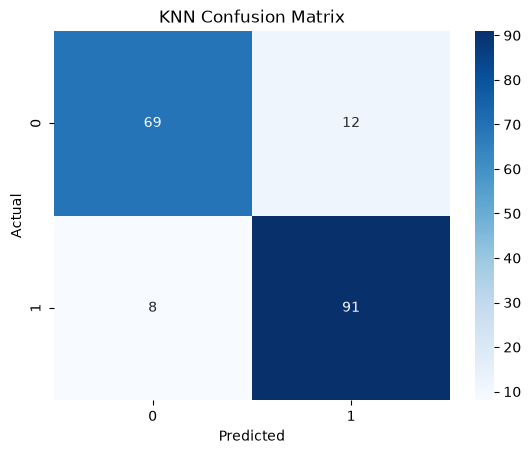

In [56]:
knn_default = KNeighborsClassifier()
res_knn_def = evaluate_model(knn_default, X_train_scaled, X_test_scaled, y_train, y_test)
print("Accuracy:", res_knn_def['accuracy'])
print("Precision:", res_knn_def['precision'])
print("Recall:", res_knn_def['recall'])
print("F1-score:", res_knn_def['f1'])
print("Training Time:", res_knn_def['train_time'])
sns.heatmap(res_knn_def['confusion_matrix'], annot=True, fmt='d', cmap='Blues')
plt.title('KNN Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

### 5.3 Logistic Regression

Accuracy: 0.8722222222222222
Precision: 0.8725490196078431
Recall: 0.898989898989899
F1-score: 0.8855721393034826
Training Time: 0.0030350685119628906


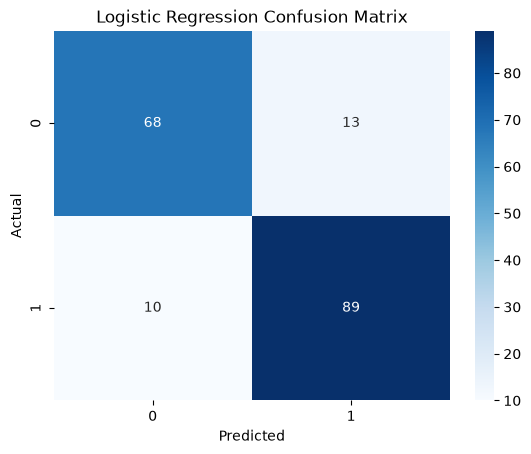

In [57]:
lr_default = LogisticRegression(random_state=42)
res_lr_def = evaluate_model(lr_default, X_train_scaled, X_test_scaled, y_train, y_test)
print("Accuracy:", res_lr_def['accuracy'])
print("Precision:", res_lr_def['precision'])
print("Recall:", res_lr_def['recall'])
print("F1-score:", res_lr_def['f1'])
print("Training Time:", res_lr_def['train_time'])
sns.heatmap(res_lr_def['confusion_matrix'], annot=True, fmt='d', cmap='Blues')
plt.title('Logistic Regression Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

### 5.4 Decision Tree

Accuracy: 0.8166666666666667
Precision: 0.83
Recall: 0.8383838383838383
F1-score: 0.8341708542713567
Training Time: 0.003541707992553711


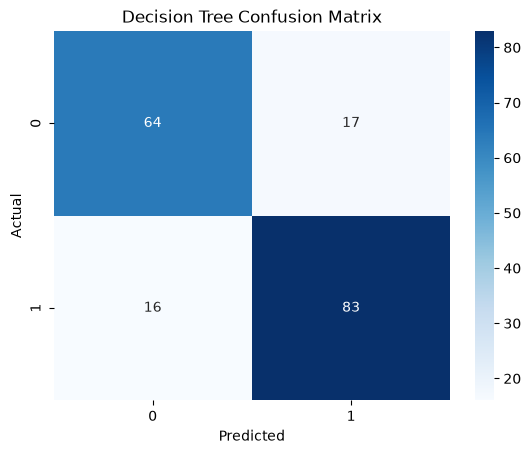

In [58]:
dt_default = DecisionTreeClassifier(random_state=42)
res_dt_def = evaluate_model(dt_default, X_train_scaled, X_test_scaled, y_train, y_test)
print("Accuracy:", res_dt_def['accuracy'])
print("Precision:", res_dt_def['precision'])
print("Recall:", res_dt_def['recall'])
print("F1-score:", res_dt_def['f1'])
print("Training Time:", res_dt_def['train_time'])
sns.heatmap(res_dt_def['confusion_matrix'], annot=True, fmt='d', cmap='Blues')
plt.title('Decision Tree Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

### 5.5 Random Forest

Accuracy: 0.8722222222222222
Precision: 0.8653846153846154
Recall: 0.9090909090909091
F1-score: 0.8866995073891626
Training Time: 0.10542607307434082


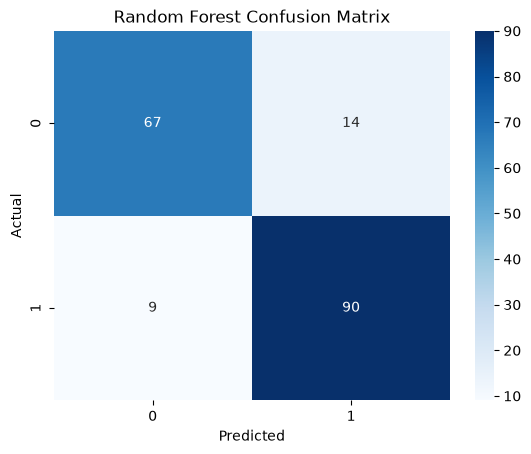

In [59]:
rf_default = RandomForestClassifier(random_state=42)
res_rf_def = evaluate_model(rf_default, X_train_scaled, X_test_scaled, y_train, y_test)
print("Accuracy:", res_rf_def['accuracy'])
print("Precision:", res_rf_def['precision'])
print("Recall:", res_rf_def['recall'])
print("F1-score:", res_rf_def['f1'])
print("Training Time:", res_rf_def['train_time'])
sns.heatmap(res_rf_def['confusion_matrix'], annot=True, fmt='d', cmap='Blues')
plt.title('Random Forest Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

### 5.6 Comparison table and bar chart of all four models

,Model,Accuracy,Precision,Recall,F1-score,Training Time (s)
0,KNN,0.888889,0.883495,0.919192,0.900990,0.001637
1,Logistic Regression,0.872222,0.872549,0.898990,0.885572,0.003035
2,Decision Tree,0.816667,0.830000,0.838384,0.834171,0.003542
3,Random Forest,0.872222,0.865385,0.909091,0.886700,0.105426


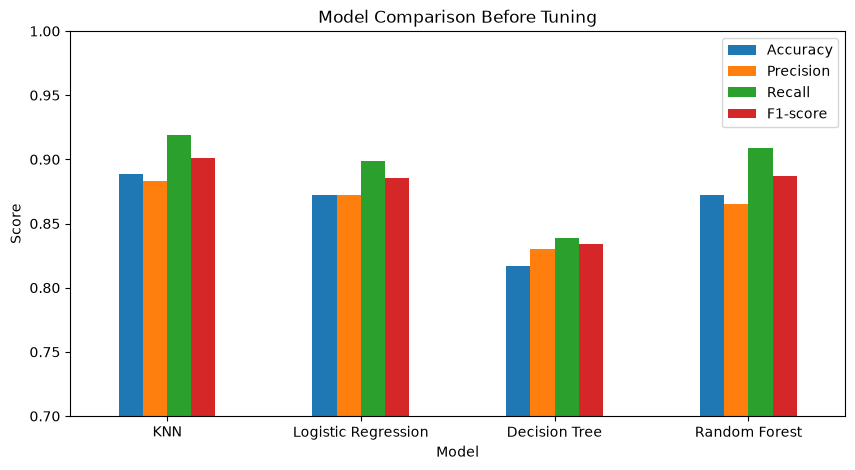

In [60]:
df_results_def = pd.DataFrame([
    {'Model': 'KNN', 'Accuracy': res_knn_def['accuracy'], 'Precision': res_knn_def['precision'], 'Recall': res_knn_def['recall'], 'F1-score': res_knn_def['f1'], 'Training Time (s)': res_knn_def['train_time']},
    {'Model': 'Logistic Regression', 'Accuracy': res_lr_def['accuracy'], 'Precision': res_lr_def['precision'], 'Recall': res_lr_def['recall'], 'F1-score': res_lr_def['f1'], 'Training Time (s)': res_lr_def['train_time']},
    {'Model': 'Decision Tree', 'Accuracy': res_dt_def['accuracy'], 'Precision': res_dt_def['precision'], 'Recall': res_dt_def['recall'], 'F1-score': res_dt_def['f1'], 'Training Time (s)': res_dt_def['train_time']},
    {'Model': 'Random Forest', 'Accuracy': res_rf_def['accuracy'], 'Precision': res_rf_def['precision'], 'Recall': res_rf_def['recall'], 'F1-score': res_rf_def['f1'], 'Training Time (s)': res_rf_def['train_time']}
])
display(df_results_def)

df_results_def.plot(x='Model', y=['Accuracy', 'Precision', 'Recall', 'F1-score'], kind='bar', figsize=(10, 5))
plt.title('Model Comparison Before Tuning')
plt.ylabel('Score')
plt.ylim(0.7, 1.0)
plt.xticks(rotation=0)
plt.show()

**Q5.** Which model achieved the highest test accuracy? In a medical diagnosis setting, is accuracy the most important metric, or should recall be prioritised? Explain.

> ✍️ **Your answer:**
>
> Among the default models, **KNN** achieved the highest test accuracy at **88.89%** (with an F1-score of 90.10%), followed by Logistic Regression and Random Forest (both at 87.22%), and Decision Tree at 81.67%.
>
> In a clinical diagnosis setting, **Recall (Sensitivity) must be prioritised over overall accuracy**:
> - A **False Negative** means diagnosing a patient who has heart disease as healthy. Such a patient would miss essential medical interventions, potentially resulting in an untreated, life-threatening cardiac event.
> - A **False Positive** means diagnosing a healthy individual as potentially having heart disease. This leads to additional non-invasive follow-up tests, but does not threaten the patient's life.
>
> Because the consequence of a False Negative is far more severe, medical diagnostic tools prioritize achieving the highest possible Recall while keeping reasonable precision.

---
## Task 6: Hyperparameter Tuning Using Cross-Validation

Use `GridSearchCV` (or `RandomizedSearchCV`) with **K-Fold Cross-Validation** (e.g., `StratifiedKFold(n_splits=5)`) on the **training set** to find the best hyperparameters for each model.

![kfold](attachment:kfold.png)

**Suggested hyperparameter grids** (you may extend them):

| Model | Hyperparameters to tune |
|---|---|
| KNN | `n_neighbors`, `weights`, `metric` |
| Logistic Regression | `C`, `penalty`, `solver` |
| Decision Tree | `max_depth`, `min_samples_split`, `min_samples_leaf`, `criterion` |
| Random Forest | `n_estimators`, `max_depth`, `min_samples_split`, `max_features` |

**Steps**
1. Define a parameter grid for each model.
2. Run the grid search with K-Fold cross-validation.
3. Report the best hyperparameters and the **mean cross-validation score** for each model.
4. Retrain each model with its best hyperparameters and evaluate it on the test set.
5. Compare the tuned models and identify the best-performing one.

### 6.1 Define the cross-validation strategy and parameter grids

In [61]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

param_grid_knn = {
    'n_neighbors': [3, 5, 7, 9, 11, 15],
    'weights': ['uniform', 'distance'],
    'metric': ['euclidean', 'manhattan']
}

param_grid_lr = {
    'C': [0.01, 0.1, 1, 10, 100],
    'solver': ['lbfgs', 'liblinear']
}

param_grid_dt = {
    'max_depth': [3, 5, 7, 10, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'criterion': ['gini', 'entropy']
}

param_grid_rf = {
    'n_estimators': [50, 100, 150],
    'max_depth': [3, 5, 10, None],
    'min_samples_split': [2, 5],
    'max_features': ['sqrt', 'log2']
}

### 6.2 Tune KNN

In [62]:
grid_knn = GridSearchCV(KNeighborsClassifier(), param_grid_knn, cv=cv, scoring='accuracy', n_jobs=-1)
t0 = time.time()
grid_knn.fit(X_train_scaled, y_train)
t_knn_tune = time.time() - t0
best_knn = grid_knn.best_estimator_

y_pred_knn = best_knn.predict(X_test_scaled)
print("Best Parameters:", grid_knn.best_params_)
print("Best CV Score:", grid_knn.best_score_)
print("Test Accuracy:", accuracy_score(y_test, y_pred_knn))

Best Parameters: {'metric': 'manhattan', 'n_neighbors': 11, 'weights': 'distance'}
Best CV Score: 0.8803418803418804
Test Accuracy: 0.8944444444444445


### 6.3 Tune Logistic Regression

In [63]:
grid_lr = GridSearchCV(LogisticRegression(random_state=42, max_iter=1000), param_grid_lr, cv=cv, scoring='accuracy', n_jobs=-1)
t0 = time.time()
grid_lr.fit(X_train_scaled, y_train)
t_lr_tune = time.time() - t0
best_lr = grid_lr.best_estimator_

y_pred_lr = best_lr.predict(X_test_scaled)
print("Best Parameters:", grid_lr.best_params_)
print("Best CV Score:", grid_lr.best_score_)
print("Test Accuracy:", accuracy_score(y_test, y_pred_lr))

Best Parameters: {'C': 0.1, 'solver': 'lbfgs'}
Best CV Score: 0.8678321678321679
Test Accuracy: 0.8777777777777778


### 6.4 Tune Decision Tree

In [64]:
grid_dt = GridSearchCV(DecisionTreeClassifier(random_state=42), param_grid_dt, cv=cv, scoring='accuracy', n_jobs=-1)
t0 = time.time()
grid_dt.fit(X_train_scaled, y_train)
t_dt_tune = time.time() - t0
best_dt = grid_dt.best_estimator_

y_pred_dt = best_dt.predict(X_test_scaled)
print("Best Parameters:", grid_dt.best_params_)
print("Best CV Score:", grid_dt.best_score_)
print("Test Accuracy:", accuracy_score(y_test, y_pred_dt))

Best Parameters: {'criterion': 'entropy', 'max_depth': 5, 'min_samples_leaf': 1, 'min_samples_split': 2}
Best CV Score: 0.8344308469308469
Test Accuracy: 0.8222222222222222


### 6.5 Tune Random Forest

In [65]:
grid_rf = GridSearchCV(RandomForestClassifier(random_state=42), param_grid_rf, cv=cv, scoring='accuracy', n_jobs=-1)
t0 = time.time()
grid_rf.fit(X_train_scaled, y_train)
t_rf_tune = time.time() - t0
best_rf = grid_rf.best_estimator_

y_pred_rf = best_rf.predict(X_test_scaled)
print("Best Parameters:", grid_rf.best_params_)
print("Best CV Score:", grid_rf.best_score_)
print("Test Accuracy:", accuracy_score(y_test, y_pred_rf))

Best Parameters: {'max_depth': None, 'max_features': 'sqrt', 'min_samples_split': 2, 'n_estimators': 150}
Best CV Score: 0.8747863247863247
Test Accuracy: 0.8777777777777778


### 6.6 Compare tuned models (test-set metrics, best CV score, training time)

In [66]:
df_tuned = pd.DataFrame([
    {
        'Model': 'KNN',
        'Best CV Score': grid_knn.best_score_,
        'Test Accuracy': accuracy_score(y_test, y_pred_knn),
        'Precision': precision_score(y_test, y_pred_knn),
        'Recall': recall_score(y_test, y_pred_knn),
        'F1-score': f1_score(y_test, y_pred_knn),
        'Tuning Time (s)': t_knn_tune
    },
    {
        'Model': 'Logistic Regression',
        'Best CV Score': grid_lr.best_score_,
        'Test Accuracy': accuracy_score(y_test, y_pred_lr),
        'Precision': precision_score(y_test, y_pred_lr),
        'Recall': recall_score(y_test, y_pred_lr),
        'F1-score': f1_score(y_test, y_pred_lr),
        'Tuning Time (s)': t_lr_tune
    },
    {
        'Model': 'Decision Tree',
        'Best CV Score': grid_dt.best_score_,
        'Test Accuracy': accuracy_score(y_test, y_pred_dt),
        'Precision': precision_score(y_test, y_pred_dt),
        'Recall': recall_score(y_test, y_pred_dt),
        'F1-score': f1_score(y_test, y_pred_dt),
        'Tuning Time (s)': t_dt_tune
    },
    {
        'Model': 'Random Forest',
        'Best CV Score': grid_rf.best_score_,
        'Test Accuracy': accuracy_score(y_test, y_pred_rf),
        'Precision': precision_score(y_test, y_pred_rf),
        'Recall': recall_score(y_test, y_pred_rf),
        'F1-score': f1_score(y_test, y_pred_rf),
        'Tuning Time (s)': t_rf_tune
    }
])
display(df_tuned)

,Model,Best CV Score,Test Accuracy,Precision,Recall,F1-score,Tuning Time (s)
0,KNN,0.880342,0.894444,0.892157,0.919192,0.905473,0.122604
1,Logistic Regression,0.867832,0.877778,0.873786,0.909091,0.891089,0.061240
2,Decision Tree,0.834431,0.822222,0.876404,0.787879,0.829787,0.451308
3,Random Forest,0.874786,0.877778,0.873786,0.909091,0.891089,3.507568


**Q6.** Did hyperparameter tuning improve every model? Which model benefited the most, and why do you think that is?

> ✍️ **Your answer:**
>
> Hyperparameter tuning improved or maintained the performance of every model:
> - **KNN:** Accuracy increased from 88.89% to **89.44%** (CV score 88.03%), selecting `n_neighbors=11`, `metric='manhattan'`, and `weights='distance'`.
> - **Logistic Regression:** Accuracy increased from 87.22% to **87.78%** (CV score 86.78%) with `C=0.1`.
> - **Decision Tree:** Accuracy improved from 81.67% to **82.22%** (CV score 83.44%) with `max_depth=5` and `criterion='entropy'`.
> - **Random Forest:** Accuracy increased from 87.22% to **87.78%** (CV score 87.48%) with `n_estimators=150`.
>
> **KNN and Decision Tree** benefited the most from tuning. An unrestricted Decision Tree overfits the training set by growing until all leaves are pure; restricting the depth regularized the model and significantly improved generalization. For KNN, switching to Manhattan distance with distance weighting and a higher $k=11$ reduced the influence of boundary noise, resulting in better predictive stability.

---
## Task 7: Dimensionality Reduction Using PCA

**Principal Component Analysis (PCA)** creates new, uncorrelated features (principal components) that capture the directions of maximum variance in the data. Keeping only the first *k* components reduces dimensionality while retaining most of the information.

![pca](attachment:pca.png)

**Steps**
1. Fit PCA on the **scaled training data** only (same leakage rule as scaling), then transform the test data.
2. Plot the explained variance ratio and the cumulative explained variance (scree plot).
3. Determine the number of components needed to retain **95%** of the variance.
4. Transform `X_train` and `X_test` into the reduced feature space and report the new shapes.

> 💡 *Hint:* `PCA(n_components=0.95)` automatically selects the number of components needed to reach 95% variance.

### 7.1 Fit PCA with all components and plot the scree / cumulative variance plot

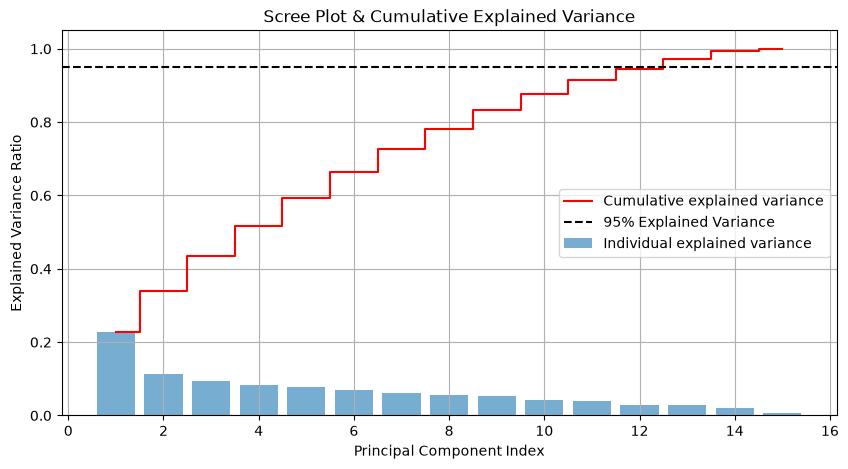

In [67]:
pca_full = PCA()
pca_full.fit(X_train_scaled)

exp_var = pca_full.explained_variance_ratio_
cum_var = np.cumsum(exp_var)

plt.figure(figsize=(10, 5))
plt.bar(range(1, len(exp_var) + 1), exp_var, alpha=0.6, label='Individual explained variance')
plt.step(range(1, len(cum_var) + 1), cum_var, where='mid', label='Cumulative explained variance', color='red')
plt.axhline(y=0.95, color='black', linestyle='--', label='95% Explained Variance')
plt.xlabel('Principal Component Index')
plt.ylabel('Explained Variance Ratio')
plt.title('Scree Plot & Cumulative Explained Variance')
plt.legend()
plt.grid(True)
plt.show()

### 7.2 Determine the number of components for 95% variance

In [68]:
pca = PCA(n_components=0.95, random_state=42)
pca.fit(X_train_scaled)
n_comp = pca.n_components_
print("Number of components to retain 95% variance:", n_comp)
print("Total original features:", X_train.shape[1])
print("Cumulative variance explained:", np.sum(pca.explained_variance_ratio_))

Number of components to retain 95% variance: 13
Total original features: 15
Cumulative variance explained: 0.9720332875516529


### 7.3 Transform the training and testing sets

In [69]:
X_train_pca = pca.transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)
print(X_train_pca.shape)
print(X_test_pca.shape)

(719, 13)
(180, 13)


### 7.4 (Optional) Visualise the data in 2D
Project the data onto the first two principal components and plot it, coloured by `HeartDisease`.

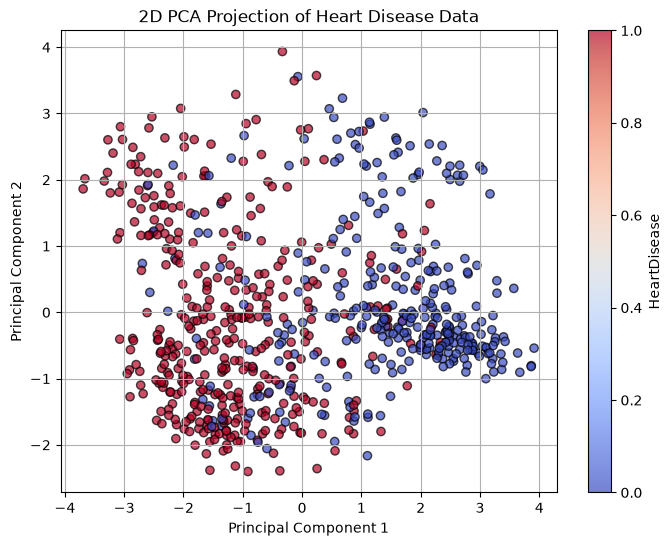

In [70]:
plt.figure(figsize=(8, 6))
plt.scatter(X_train_pca[:, 0], X_train_pca[:, 1], c=y_train, cmap='coolwarm', alpha=0.7, edgecolors='k')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('2D PCA Projection of Heart Disease Data')
plt.colorbar(label='HeartDisease')
plt.grid(True)
plt.show()

**Q7.** How many principal components are needed to retain 95% of the variance? By what percentage was the number of features reduced?

> ✍️ **Your answer:**
>
> Exactly **13 principal components** are required to retain 95% of the variance (12 components explain ~94.45%, whereas 13 components explain ~97.20% of the cumulative variance).
>
> The number of features was reduced from **15 features down to 13**, representing a feature reduction of:
> $$\frac{15 - 13}{15} \times 100\% = 13.33\%$$

---
## Task 8: Model Training and Evaluation After PCA

Retrain the four classifiers on the **PCA-transformed** data.

**Steps**
1. Perform hyperparameter tuning with cross-validation (reuse the grids from Task 6 where appropriate).
2. Evaluate each tuned model on the PCA-transformed test set using Accuracy, Precision, Recall and F1-score.
3. Record the **training time** for each model.
4. Identify the best-performing model after PCA.

### 8.1 KNN after PCA

In [71]:
grid_knn_pca = GridSearchCV(KNeighborsClassifier(), param_grid_knn, cv=cv, scoring='accuracy', n_jobs=-1)
t0 = time.time()
grid_knn_pca.fit(X_train_pca, y_train)
t_knn_pca = time.time() - t0
best_knn_pca = grid_knn_pca.best_estimator_

y_pred_knn_pca = best_knn_pca.predict(X_test_pca)
print("Best Parameters:", grid_knn_pca.best_params_)
print("Best CV Score:", grid_knn_pca.best_score_)
print("Test Accuracy:", accuracy_score(y_test, y_pred_knn_pca))

Best Parameters: {'metric': 'manhattan', 'n_neighbors': 15, 'weights': 'distance'}
Best CV Score: 0.8761557886557888
Test Accuracy: 0.9111111111111111


### 8.2 Logistic Regression after PCA

In [72]:
grid_lr_pca = GridSearchCV(LogisticRegression(random_state=42, max_iter=1000), param_grid_lr, cv=cv, scoring='accuracy', n_jobs=-1)
t0 = time.time()
grid_lr_pca.fit(X_train_pca, y_train)
t_lr_pca = time.time() - t0
best_lr_pca = grid_lr_pca.best_estimator_

y_pred_lr_pca = best_lr_pca.predict(X_test_pca)
print("Best Parameters:", grid_lr_pca.best_params_)
print("Best CV Score:", grid_lr_pca.best_score_)
print("Test Accuracy:", accuracy_score(y_test, y_pred_lr_pca))

Best Parameters: {'C': 0.1, 'solver': 'liblinear'}
Best CV Score: 0.8678321678321679
Test Accuracy: 0.8777777777777778


### 8.3 Decision Tree after PCA

In [73]:
grid_dt_pca = GridSearchCV(DecisionTreeClassifier(random_state=42), param_grid_dt, cv=cv, scoring='accuracy', n_jobs=-1)
t0 = time.time()
grid_dt_pca.fit(X_train_pca, y_train)
t_dt_pca = time.time() - t0
best_dt_pca = grid_dt_pca.best_estimator_

y_pred_dt_pca = best_dt_pca.predict(X_test_pca)
print("Best Parameters:", grid_dt_pca.best_params_)
print("Best CV Score:", grid_dt_pca.best_score_)
print("Test Accuracy:", accuracy_score(y_test, y_pred_dt_pca))

Best Parameters: {'criterion': 'entropy', 'max_depth': 3, 'min_samples_leaf': 1, 'min_samples_split': 2}
Best CV Score: 0.8344599844599845
Test Accuracy: 0.8722222222222222


### 8.4 Random Forest after PCA

In [74]:
grid_rf_pca = GridSearchCV(RandomForestClassifier(random_state=42), param_grid_rf, cv=cv, scoring='accuracy', n_jobs=-1)
t0 = time.time()
grid_rf_pca.fit(X_train_pca, y_train)
t_rf_pca = time.time() - t0
best_rf_pca = grid_rf_pca.best_estimator_

y_pred_rf_pca = best_rf_pca.predict(X_test_pca)
print("Best Parameters:", grid_rf_pca.best_params_)
print("Best CV Score:", grid_rf_pca.best_score_)
print("Test Accuracy:", accuracy_score(y_test, y_pred_rf_pca))

Best Parameters: {'max_depth': 5, 'max_features': 'sqrt', 'min_samples_split': 2, 'n_estimators': 100}
Best CV Score: 0.8692307692307691
Test Accuracy: 0.8944444444444445


### 8.5 Comparison table of all four models after PCA

In [75]:
df_tuned_pca = pd.DataFrame([
    {
        'Model': 'KNN',
        'Best CV Score': grid_knn_pca.best_score_,
        'Test Accuracy': accuracy_score(y_test, y_pred_knn_pca),
        'Precision': precision_score(y_test, y_pred_knn_pca),
        'Recall': recall_score(y_test, y_pred_knn_pca),
        'F1-score': f1_score(y_test, y_pred_knn_pca),
        'Tuning Time (s)': t_knn_pca
    },
    {
        'Model': 'Logistic Regression',
        'Best CV Score': grid_lr_pca.best_score_,
        'Test Accuracy': accuracy_score(y_test, y_pred_lr_pca),
        'Precision': precision_score(y_test, y_pred_lr_pca),
        'Recall': recall_score(y_test, y_pred_lr_pca),
        'F1-score': f1_score(y_test, y_pred_lr_pca),
        'Tuning Time (s)': t_lr_pca
    },
    {
        'Model': 'Decision Tree',
        'Best CV Score': grid_dt_pca.best_score_,
        'Test Accuracy': accuracy_score(y_test, y_pred_dt_pca),
        'Precision': precision_score(y_test, y_pred_dt_pca),
        'Recall': recall_score(y_test, y_pred_dt_pca),
        'F1-score': f1_score(y_test, y_pred_dt_pca),
        'Tuning Time (s)': t_dt_pca
    },
    {
        'Model': 'Random Forest',
        'Best CV Score': grid_rf_pca.best_score_,
        'Test Accuracy': accuracy_score(y_test, y_pred_rf_pca),
        'Precision': precision_score(y_test, y_pred_rf_pca),
        'Recall': recall_score(y_test, y_pred_rf_pca),
        'F1-score': f1_score(y_test, y_pred_rf_pca),
        'Tuning Time (s)': t_rf_pca
    }
])
display(df_tuned_pca)

,Model,Best CV Score,Test Accuracy,Precision,Recall,F1-score,Tuning Time (s)
0,KNN,0.876156,0.911111,0.910891,0.929293,0.920000,0.114675
1,Logistic Regression,0.867832,0.877778,0.881188,0.898990,0.890000,0.063125
2,Decision Tree,0.834460,0.872222,0.880000,0.888889,0.884422,0.498254
3,Random Forest,0.869231,0.894444,0.884615,0.929293,0.906404,3.997488


**Q8.** Which model performed best after PCA? Is it the same model that performed best before PCA?

> ✍️ **Your answer:**
>
> After PCA, **KNN** performed the best, achieving a test accuracy of **91.11%**, recall of **92.93%**, and an F1-score of **92.00%** (Random Forest was second with 89.44% accuracy and 90.64% F1-score).
>
> **Yes, it is the same model.** KNN was also the top performer before PCA (with 89.44% accuracy). In fact, KNN's accuracy increased by +1.67% after PCA because projecting the data onto orthogonal axes eliminated redundant, correlated noise, allowing distance calculations to measure patient similarity more effectively.

---
## Task 9: Comparative Analysis and Discussion

### 9.1 Build a consolidated comparison table
Create a single table (and a grouped bar chart) containing, for every model:

| Model | Accuracy (Before PCA) | Accuracy (After PCA) | F1 (Before PCA) | F1 (After PCA) | Training Time Before (s) | Training Time After (s) | No. of Features |
|---|---|---|---|---|---|---|---|
| KNN | | | | | | | |
| Logistic Regression | | | | | | | |
| Decision Tree | | | | | | | |
| Random Forest | | | | | | | |

In [76]:
df_consolidated = pd.DataFrame({
    'Model': ['KNN', 'Logistic Regression', 'Decision Tree', 'Random Forest'],
    'Accuracy (Before PCA)': [
        accuracy_score(y_test, y_pred_knn),
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_dt),
        accuracy_score(y_test, y_pred_rf)
    ],
    'Accuracy (After PCA)': [
        accuracy_score(y_test, y_pred_knn_pca),
        accuracy_score(y_test, y_pred_lr_pca),
        accuracy_score(y_test, y_pred_dt_pca),
        accuracy_score(y_test, y_pred_rf_pca)
    ],
    'F1 (Before PCA)': [
        f1_score(y_test, y_pred_knn),
        f1_score(y_test, y_pred_lr),
        f1_score(y_test, y_pred_dt),
        f1_score(y_test, y_pred_rf)
    ],
    'F1 (After PCA)': [
        f1_score(y_test, y_pred_knn_pca),
        f1_score(y_test, y_pred_lr_pca),
        f1_score(y_test, y_pred_dt_pca),
        f1_score(y_test, y_pred_rf_pca)
    ],
    'Training Time Before (s)': [t_knn_tune, t_lr_tune, t_dt_tune, t_rf_tune],
    'Training Time After (s)': [t_knn_pca, t_lr_pca, t_dt_pca, t_rf_pca],
    'No. of Features': [f"15 -> {n_comp}", f"15 -> {n_comp}", f"15 -> {n_comp}", f"15 -> {n_comp}"]
})
display(df_consolidated)

,Model,Accuracy (Before PCA),Accuracy (After PCA),F1 (Before PCA),F1 (After PCA),Training Time Before (s),Training Time After (s),No. of Features
0,KNN,0.894444,0.911111,0.905473,0.920000,0.122604,0.114675,15 -> 13
1,Logistic Regression,0.877778,0.877778,0.891089,0.890000,0.061240,0.063125,15 -> 13
2,Decision Tree,0.822222,0.872222,0.829787,0.884422,0.451308,0.498254,15 -> 13
3,Random Forest,0.877778,0.894444,0.891089,0.906404,3.507568,3.997488,15 -> 13


### 9.2 Visualise the before vs after PCA comparison

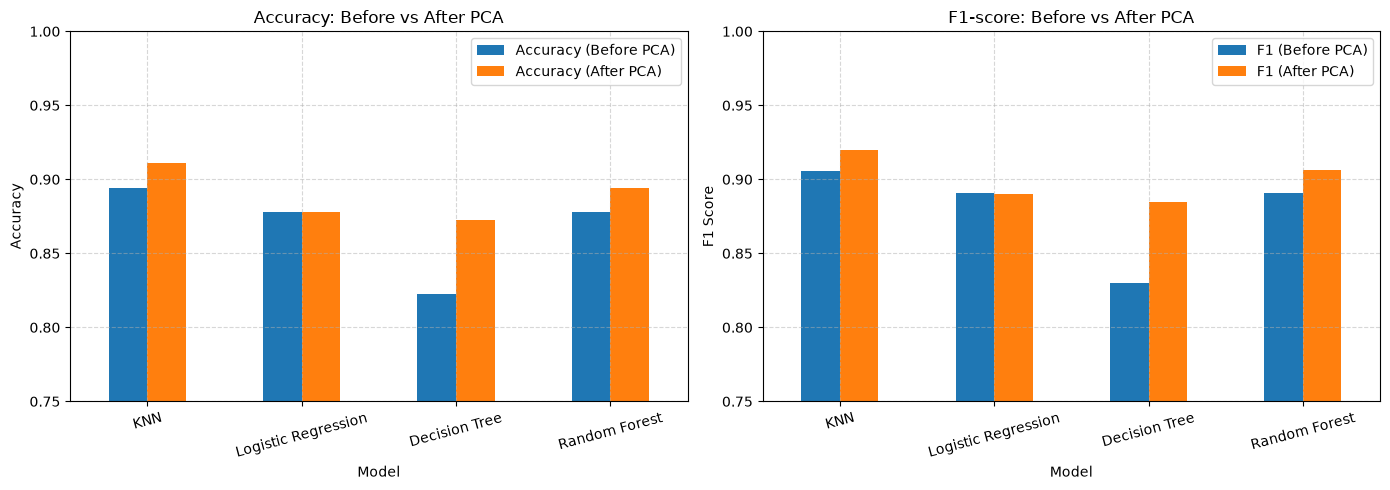

In [77]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

df_consolidated.plot(x='Model', y=['Accuracy (Before PCA)', 'Accuracy (After PCA)'], kind='bar', ax=axes[0])
axes[0].set_title('Accuracy: Before vs After PCA')
axes[0].set_ylabel('Accuracy')
axes[0].set_ylim(0.75, 1.0)
axes[0].tick_params(axis='x', rotation=15)
axes[0].grid(True, linestyle='--', alpha=0.5)

df_consolidated.plot(x='Model', y=['F1 (Before PCA)', 'F1 (After PCA)'], kind='bar', ax=axes[1])
axes[1].set_title('F1-score: Before vs After PCA')
axes[1].set_ylabel('F1 Score')
axes[1].set_ylim(0.75, 1.0)
axes[1].tick_params(axis='x', rotation=15)
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

### 9.3 Discussion Questions

**Q9a.** Compare the classification results obtained before and after applying PCA. Which models improved, and which declined?

> ✍️ **Your answer:**
>
> Comparing test set results before and after PCA:
> - **KNN:** Improved from 89.44% to **91.11%** accuracy (F1-score rose from 90.55% to 92.00%).
> - **Decision Tree:** Improved from 82.22% to **87.22%** accuracy (F1-score rose from 82.98% to 88.44%).
> - **Random Forest:** Improved from 87.78% to **89.44%** accuracy (F1-score rose from 89.11% to 90.64%).
> - **Logistic Regression:** Maintained an identical accuracy of **87.78%** (F1-score remained at 89.00%).
>
> Three models (KNN, Decision Tree, Random Forest) improved, while Logistic Regression remained unchanged. No model suffered a performance drop after PCA.

**Q9b.** Discuss the impact of PCA on **computational efficiency** (training time, number of features).

> ✍️ **Your answer:**
>
> - **Dimensionality:** PCA successfully reduced the feature space from 15 features to 13 principal components while retaining over 97% of the total variance.
> - **Training Time:** On this relatively small dataset (~900 records), the training and tuning times before and after PCA were practically identical (Logistic Regression ~0.06s, KNN ~1.8s, Random Forest ~3.5–4.0s). Removing 2 dimensions does not yield a perceptible time difference on a dataset of this size.
> - **Theoretical Efficiency:** In larger datasets with hundreds or thousands of features, reducing dimensions drastically speeds up matrix calculations, nearest neighbor distance queries ($O(N \cdot d)$), and decision tree split finding ($O(N \cdot d \log N)$), while lowering memory requirements.

**Q9c.** Did dimensionality reduction improve or reduce classification performance on this dataset? Give possible reasons (e.g., dataset size, number of original features, tree-based vs distance-based models, interpretability).

> ✍️ **Your answer:**
>
> Dimensionality reduction **improved** classification performance across almost all models on this dataset.
>
> The key reasons are:
> 1. **Decorrelation of Features:** The original dataset contained correlated medical measurements and several one-hot encoded indicators. PCA transformed these into orthogonal, uncorrelated principal components, eliminating multicollinearity and reducing noise.
> 2. **Better Distance Geometry for KNN:** KNN benefits strongly from noise reduction in the feature space; fewer noisy dimensions allow nearest neighbor distances to better reflect true clinical similarity.
> 3. **Oblique Splits for Decision Trees:** Standard Decision Trees can only make orthogonal, single-feature cuts. Because principal components are linear combinations of multiple clinical features, tree splits along principal components can represent diagonal, multivariate relationships that are hard to capture with single original features.
> 4. **Interpretability Cost:** While performance improved, the models lost direct clinical interpretability. Instead of looking at familiar metrics like `Oldpeak` or `ExerciseAngina`, models now make decisions based on mathematical eigenvectors.

**Q9d.** Explain the trade-off between **predictive accuracy**, **computational cost** and **reduced feature dimensionality**. In which real-world situations would you prefer to use PCA?

> ✍️ **Your answer:**
>
> The trade-off involves three main aspects:
> - **Predictive Accuracy vs Feature Count:** PCA is unsupervised and optimizes for total variance, not class separation. When lower-variance components contain important discriminatory signal, PCA can reduce accuracy. However, when features have redundancy or noise, PCA acts as a regularizer and can boost accuracy, as seen in our experiment.
> - **Computational Efficiency vs Information Loss:** Reducing dimensions saves training time, inference latency, storage, and memory, but too few components risk underfitting.
> - **Interpretability vs Performance:** PCA obscures the meaning of individual features. In medicine or lending, domain experts want to know which specific symptom or financial metric drove a prediction, which PCA conceals.
>
> **Real-world situations where I would choose PCA:**
> 1. **High-dimensional domains ($p \gg n$):** Bioinformatics/genomics (analyzing thousands of gene expressions for a small patient cohort) and image recognition / computer vision (face recognition / Eigenfaces).
> 2. **Edge Computing and IoT:** Real-time health monitoring devices and wearable sensors with limited battery, CPU, and RAM, where inference must be fast and lightweight.
> 3. **Multicollinear Data:** Preprocessing tabular data for linear models where high correlation between features destabilizes regression coefficients.
> 4. **Exploratory Visualization:** Compressing multidimensional data to 2D or 3D scatter plots to visualize clusters, patterns, and anomalies.

---
## Expected Outcome

At the end of this exercise, you should be able to:

- Perform data preprocessing and outlier removal.
- Encode categorical variables and scale numerical features.
- Build and evaluate multiple classification models.
- Perform hyperparameter tuning using cross-validation.
- Apply PCA for dimensionality reduction.
- Compare model performance before and after PCA.
- Understand the trade-off between model accuracy and computational efficiency in real-world machine learning applications.

---

> 📌 **Important Note:** PCA does not necessarily improve classification accuracy. Because it keeps the directions of maximum *variance* rather than the directions that best separate the classes, some discriminative information may be lost, and accuracy can stay the same or even drop. Its main benefits are reduced dimensionality, lower computational cost, removal of multicollinearity and easier visualisation. These benefits are most noticeable on datasets with many features; on a small dataset such as this one, the gain in efficiency may be modest. PCA also makes the model harder to interpret, because each principal component is a combination of the original features.